# 03 · Models — Domestic Flight Price (Regression)

**Goal:** try every model family taught in Part 1, each one motivated by an EDA finding, and compare them fairly.

**Fair comparison rules** (all enforced by `src/evaluate.py`):
- the same cleaned data (`load_clean()`, 15,167 rows) and the same preprocessing (`make_preprocessor()`),
- the same 5 CV folds (`SEED = 42`), with preprocessing re-fitted inside each fold,
- the competition metric, **R² on raw price** (higher is better; Kaggle top ≈ 0.96, our baseline 0.29),
- every model logged to `results/regression/experiments.csv`.

We also report **train R²** (the score on the rows the model was fitted on). The gap between train R² and CV R² is the practical face of the bias–variance trade-off from lecture: a small gap with a low score means the model is too simple (**underfitting, high bias**); a big gap means it memorised its training rows (**overfitting, high variance**).

| # | Model | Question it answers |
|---|---|---|
| 1 | OLS (least squares) | How far does a plain additive linear model get? |
| 2 | OLS on log(price) | Does fixing the skew help, given the metric is R² on *raw* price? |
| 3 | OLS + class interactions | EDA: does letting every feature act differently per class help? |
| 4 | Separate OLS per class | Same idea, built as two models — is it different from 3? |
| 5 | Polynomial (degree 2) + OLS | Can pairwise interactions between *all* features capture airline × class × route effects? |
| 6 | Polynomial + Ridge (L2) | Does shrinking ~800 coefficients reduce variance? |
| 7 | Class interactions + Lasso (L1) | Which features can be dropped entirely? |
| 8 | Decision tree (fully grown) | Do trees find the interactions on their own? |
| 9 | Pruned decision tree | Does limiting the tree's growth fix its overfitting? |

**What this cell does:** Standard opening: auto-reload, make `src/` importable, import `config`.

**Why:** Same as every notebook.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

**What this cell does:** Imports libraries and project modules, loads the cleaned data, and silences one specific sklearn warning.

**Why:** During CV, a rare airline can appear in a validation fold but not in that fold's training part. The encoder then puts it in the "infrequent" column — exactly the behaviour we designed in Phase 2 — but sklearn prints a warning every time. We silence only that message so real warnings still show.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

from src import evaluate
from src.regression import preprocess as pp
from src.regression.models import ClassInteractions, PerGroupRegressor

warnings.filterwarnings("ignore", message="Found unknown categories")
TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
print("X", X.shape, "| X_test", X_test.shape)

X (15167, 10) | X_test (3898, 10)


**What this cell does:** Defines `run()`, a small wrapper that cross-validates a model, logs it, and prints CV R², train R² and RMSE in one line.

**Why:** Keeps every model section to one line of scoring code, so the notebook reads as a sequence of modelling decisions rather than boilerplate.

In [3]:
scores = {}

def run(name, model, params=None, notes=""):
    folds = evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes)
    scores[name] = folds.mean()
    print(f"{name:28s} CV R² {folds.r2.mean():.4f} ± {folds.r2.std():.4f} | train R² {folds.train_r2.mean():.4f}"
          f" | RMSE ₹{folds.rmse.mean():,.0f}")
    return folds

## Model 1 — Ordinary least squares (OLS)

The simplest model from lecture: price = w₀ + w₁x₁ + … + wₚxₚ, with weights chosen to minimise squared error. Each feature adds a fixed amount to the price regardless of the others — e.g. "Business adds ₹X" is the same for every airline. EDA says that's wrong (premium Economy ≈ budget Business), so we expect a decent but limited score.

`drop_first=True` drops one category per one-hot group (the dummy-variable trap from Phase 2), so each coefficient means "price difference relative to the dropped category".

**What this cell does:** Cross-validates plain OLS on the 34 encoded features.

**Why:** This is the reference point for every linear model that follows.

In [4]:
ols = make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())
_ = run("1_ols", ols, notes="plain least squares")

1_ols                        CV R² 0.8345 ± 0.0038 | train R² 0.8366 | RMSE ₹15,997


**What this cell does:** Fits OLS on all training rows and shows the airline coefficients (relative to the dropped first airline, Ajira Airways) and the class coefficient.

**Why:** Reading the coefficients shows the model's limitation concretely: each airline gets *one* price shift that applies to both Economy and Business tickets, even though EDA showed the airline effect is very different per class.

In [5]:
ols.fit(X, y)
coef = pd.Series(ols[-1].coef_, index=ols[:-1].get_feature_names_out())
print(f"intercept: ₹{ols[-1].intercept_:,.0f}")
coef[coef.index.str.startswith(("airline_", "flight_class_"))].sort_values().map("₹{:,.0f}".format).to_frame("coefficient")

intercept: ₹74,379


,coefficient
airline_Oceanic Airlines,"₹-33,222"
flight_class_Economy,"₹-30,837"
airline_Wayfarer Aviation,"₹-29,046"
airline_Sandpiper Air,"₹-27,535"
airline_Vandelay Aviation,"₹-25,465"
airline_Wayne Enterprises Air,"₹21,542"
airline_infrequent_sklearn,"₹49,272"
airline_Virtucon,"₹51,511"
airline_Stark Aviation,"₹53,265"
airline_Nakatomi Airlines,"₹63,055"


**Observations (Model 1)**

- **CV R² 0.8345**, train R² 0.8366. The gap is tiny (0.002), so OLS isn't overfitting at all; it's **underfitting** (high bias). It's too simple to capture the price structure, and more data wouldn't help.
- Already a huge jump over the class-median baseline (0.29).
- The coefficients show the limitation EDA predicted. Each airline gets **one** price shift for both classes. Vault-Tec Air gets +₹100,905 because it sells only Business, so its coefficient soaks up the Business premium. Oceanic gets −₹33,222 for both its Economy and its Business tickets. An additive model can't say "this airline is cheap in Economy but expensive in Business".

## Model 2 — OLS on log(price)

Same model, but trained to predict log(price); predictions are converted back with exp(). This turns the additive model into a multiplicative one (each feature multiplies the price by a factor), which suits skewed prices — but the metric is R² on **raw** rupees.

**What this cell does:** Cross-validates OLS with a log-transformed target (`evaluate.log_target` wraps the model so it trains on log(price) and predicts in rupees).

**Why:** Directly tests the Phase 2 question: does the log transform help *under this metric*?

In [6]:
_ = run("2_ols_log", evaluate.log_target(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())),
        notes="log target")

2_ols_log                    CV R² 0.8264 ± 0.0120 | train R² 0.8275 | RMSE ₹16,372


**What this cell does:** Gets out-of-fold predictions for both models and compares, per class, the average predicted price with the average true price.

**Why:** If the log model systematically under-predicts expensive tickets, it will show up as a lower average for Business. That would explain a lower R², because R² on raw price is dominated by those expensive tickets.

In [7]:
oof = pd.DataFrame({
    "class": X.flight_class.to_numpy(), "true": y.to_numpy(),
    "ols": evaluate.oof_predict(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression()), X, y, TASK),
    "ols_log": evaluate.oof_predict(evaluate.log_target(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())), X, y, TASK),
})
summary = oof.groupby("class")[["true", "ols", "ols_log"]].mean().round(0)
summary["ols_log − true"] = summary["ols_log"] - summary["true"]
display(summary)
print("negative predictions — ols:", (oof.ols < 0).sum(), "| ols_log:", (oof.ols_log < 0).sum())

,true,ols,ols_log,ols_log − true
class,,,,
Business,60408.0,60364.0,58304.0,-2104.0
Economy,8792.0,8795.0,8457.0,-335.0


negative predictions — ols: 172 | ols_log: 0


**Observations (Model 2)**

- **CV R² 0.8264, lower than Model 1 (0.8345)**, and noisier across folds (± 0.012 vs 0.004).
- The out-of-fold averages show why: the log model **systematically under-predicts**. Business is −₹2,104 on average (−3.5%), Economy −₹335. That's a known effect of training on log(price): converting back with exp() gives something closer to the *median* price for a given set of features, which is below the *mean* when prices are right-skewed. R² on raw price punishes this most on the expensive Business tickets.
- Its upside: 0 negative predictions vs 172 for plain OLS. That's real but worth less under this metric.
- **Conclusion: train on raw price** for the rest of the ladder. This is a direct consequence of the metric being R² on raw price, not log price.

## Model 3 — OLS with class interactions

EDA's main modelling recommendation: let each feature have **a different effect in each class**. `ClassInteractions` appends a copy of every feature multiplied by the class indicator (1 for one class, 0 for the other). The model then learns, e.g., "airline Stark adds ₹a in the base class and ₹a + b in the other" — still linear, still least squares, just with more columns (34 → ~67).

**What this cell does:** Cross-validates OLS on the base features plus their class interactions.

**Why:** If EDA was right that airline/stops/duration effects differ by class, this should clearly beat Model 1.

In [8]:
_ = run("3_ols_class_interactions",
        make_pipeline(pp.make_preprocessor(drop_first=True), ClassInteractions(), LinearRegression()),
        notes="every feature x class indicator")

3_ols_class_interactions     CV R² 0.8805 ± 0.0051 | train R² 0.8826 | RMSE ₹13,593


**Observations (Model 3)**

- **CV R² 0.8805 (+0.046 over Model 1).** That's the largest gain from any single idea in the linear family, and it confirms the EDA's main recommendation: features act differently per class.
- Train R² 0.8826, so the gap is still tiny. The model is still bias-limited: it has room to be more flexible.

## Model 4 — Separate OLS model per class

The plan's model #6: train one OLS on Economy rows and another on Business rows. `PerGroupRegressor` does this and routes each test row to its class's model.

**What this cell does:** Cross-validates two independent OLS models (one per class), each with its own preprocessing.

**Why:** Interacting *every* feature with class (Model 3) and fitting two separate models are mathematically the same linear model — both give each class its own intercept and its own slope for every feature. If the scores differ, the difference must come from preprocessing (here each class gets its own duration medians, scaling and rare-airline grouping), not from the model.

In [9]:
_ = run("4_ols_per_class", PerGroupRegressor(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())),
        notes="one OLS per flight_class")

4_ols_per_class              CV R² 0.8763 ± 0.0052 | train R² 0.8785 | RMSE ₹13,828


**Observations (Model 4)**

- **CV R² 0.8763, almost the same as Model 3 (0.8805).** That's expected: two separate OLS models and one OLS with every feature interacted with class are the *same* linear model in principle (each class gets its own intercept and its own slope for every feature).
- The small difference comes from **preprocessing**. Here each class gets its own duration medians and its own rare-airline grouping, from only part of the rows (e.g. an airline with 60 rows overall may fall below the 50-row threshold inside one class and be lumped into "infrequent").
- **Takeaway for the report and viva:** "separate models per class" isn't a different kind of model. It's the full class interaction. One model with interactions is the tidier way to get it and does slightly better here.

## Model 5 — Polynomial features (degree 2) + OLS

Class interactions only let features interact with *class*. EDA showed more interactions: airline tier × route, stops × airline, etc. `PolynomialFeatures(degree=2)` creates every pairwise product of the 34 features plus squares (e.g. `duration²`, `airline_X × destination_Y`) — about 600 columns. It's still linear regression, in an expanded feature space.

**What this cell does:** Cross-validates OLS on all degree-2 polynomial features.

**Why:** Tests whether broad pairwise interactions add signal beyond class interactions, and whether 600 unregularised coefficients start overfitting (watch the train-vs-CV gap and the fold-to-fold ±).

In [10]:
_ = run("5_poly2_ols", make_pipeline(pp.make_preprocessor(drop_first=True), PolynomialFeatures(2, include_bias=False),
                                     LinearRegression()), notes="degree-2 polynomial features")

5_poly2_ols                  CV R² 0.9070 ± 0.0084 | train R² 0.9329 | RMSE ₹11,977


**Observations (Model 5)**

- **CV R² 0.9070 (+0.027 over Model 3).** All pairwise interactions (e.g. premium airline × route, duration × class) add real signal beyond class interactions.
- **First visible overfitting:** train R² 0.9329 vs CV 0.9070, a gap of 0.026 (it was ~0.002 for the simpler linear models). Fold-to-fold spread also grows (± 0.0084). About 600 unpenalised coefficients start fitting noise, which sets up the case for regularisation.

## Model 6 — Polynomial features + Ridge (L2 regularisation)

Ridge minimises squared error **plus α × (sum of squared coefficients)**. The penalty pulls every coefficient towards zero; coefficients survive only if they reduce error enough to pay for themselves. Larger α = simpler, more biased model; smaller α = closer to OLS. We let CV choose α.

Ridge penalises all coefficients on the same scale, so here we keep every one-hot column (`drop_first=False`) — the penalty itself resolves the dummy-variable ambiguity.

**What this cell does:** Tries α ∈ {0.1, 1, 10, 100} on the same folds, shows all results, and logs the best one.

**Why:** α controls the bias–variance trade-off. Showing every α (not just the best) makes the trade-off visible: too small behaves like Model 5, too large underfits.

In [11]:
def ridge_poly(alpha):
    return make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=alpha))

ridge_table, ridge_best = evaluate.grid_search(ridge_poly, [{"alpha": a} for a in [0.1, 1, 10, 100]],
                                               X, y, TASK, "6_poly2_ridge", notes="degree-2 polynomial + L2")
scores["6_poly2_ridge"] = ridge_table.iloc[0]
display(ridge_table.round(4))
print("best:", ridge_best)

,alpha,r2_mean,r2_std,train_r2
0,10.0,0.9174,0.0060,0.9291
1,1.0,0.9163,0.0060,0.9324
2,0.1,0.9134,0.0054,0.9328
3,100.0,0.9053,0.0038,0.9134


best: {'alpha': 10}


**Observations (Model 6)**

- **Best α = 10: CV R² 0.9174, the best model so far.** RMSE ₹11,292, vs ₹33,152 for the baseline.
- The α sweep shows the bias–variance trade-off directly:
  - α = 0.1 → CV 0.9134, train 0.9328 (close to unpenalised Model 5: higher variance)
  - **α = 10 → CV 0.9174, train 0.9291** (gap shrinks to 0.012)
  - α = 100 → CV 0.9053, train 0.9134 (too much shrinkage: underfits)
- Same features as Model 5; only the penalty changed, and CV R² rose by 0.010. Regularisation pays off exactly where the feature count is large.

## Model 7 — Lasso (L1 regularisation) on class-interaction features

Lasso uses **α × (sum of absolute coefficients)** as the penalty. Unlike Ridge, this drives many coefficients to **exactly zero** — it performs feature selection. We use the class-interaction feature set (Model 3, ~70 columns) rather than the 600 polynomial columns: Lasso's solver is far slower (a test run on the polynomial set took over 10 minutes per setting), and with ~70 columns the list of kept features is still readable.

**What this cell does:** Tries α ∈ {10, 100, 1000} on the class-interaction features, logs the best, and counts how many coefficients each α keeps (fitted on all rows).

**Why:** Shows the trade-off Lasso offers: how much accuracy we give up for how much simpler a model.

In [12]:
def lasso_inter(alpha):
    return make_pipeline(pp.make_preprocessor(), ClassInteractions(), Lasso(alpha=alpha, max_iter=50_000))

lasso_table, lasso_best = evaluate.grid_search(lasso_inter, [{"alpha": a} for a in [10, 100, 1000]],
                                               X, y, TASK, "7_lasso_class_interactions", notes="class interactions + L1")
lasso_table["features kept"] = [int((lasso_inter(a).fit(X, y)[-1].coef_ != 0).sum()) for a in lasso_table.alpha]
lasso_table["features total"] = len(lasso_inter(10).fit(X, y)[-1].coef_)
scores["7_lasso_class_interactions"] = lasso_table.iloc[0]
lasso_table.round(4)

,alpha,r2_mean,r2_std,train_r2,features kept,features total
0,10,0.8804,0.0053,0.8824,58,78
1,100,0.8732,0.0069,0.8749,35,78
2,1000,0.7579,0.0022,0.7584,11,78


**What this cell does:** Fits Lasso with α = 100 and lists which features it dropped (coefficient exactly 0).

**Why:** α = 100 is the interesting middle point: it removes about half the features. Seeing *which* ones it discards checks the EDA's ranking of weak features (time slots, days_left) against what a model independently decides.

In [13]:
lasso100 = lasso_inter(100).fit(X, y)
coef = pd.Series(lasso100[-1].coef_, index=lasso100[:-1].get_feature_names_out())
dropped = coef[coef == 0].index
print(f"dropped {len(dropped)} of {len(coef)} features:")
print("\n".join(sorted(dropped)))

dropped 43 of 78 features:
airline_Ajira Airways
airline_Sandpiper Air x flight_class_Business
airline_Vandelay Aviation
airline_Vandelay Aviation x flight_class_Business
airline_Virtucon x flight_class_Business
airline_Wayne Enterprises Air
airline_Wayne Enterprises Air x flight_class_Business
airline_infrequent_sklearn
arrival_time_Afternoon
arrival_time_Early_Morning
arrival_time_Early_Morning x flight_class_Business
arrival_time_Evening
arrival_time_Evening x flight_class_Business
arrival_time_Late_Night
arrival_time_Morning
arrival_time_Morning x flight_class_Business
arrival_time_Night
arrival_time_Night x flight_class_Business
days_left
departure_time_Afternoon
departure_time_Early_Morning
departure_time_Evening
departure_time_Evening x flight_class_Business
departure_time_Late_Night
departure_time_Morning
departure_time_Morning x flight_class_Business
departure_time_Night
destination_city_Gotham
destination_city_Gotham x flight_class_Business
destination_city_Los Santos
destina

**Observations (Model 7)**

- **α = 10:** keeps 58 of 78 features, CV R² 0.8804, the same as unpenalised OLS on the same features (Model 3). Those 20 features contributed nothing.
- **α = 100:** keeps only **35 of 78**, CV R² 0.8732. Half the model for −0.007 R².
- **α = 1000:** 11 features, R² drops to 0.758. Too aggressive.
- **What Lasso drops at α = 100 matches the EDA ranking of weak features:**
  - almost all departure/arrival time slots (EDA 2.6: "barely matter")
  - **`days_left`** entirely (EDA 2.5: no linear trend, only a last-few-days bump)
  - **`stops`** (EDA 2.4: overlaps with duration, which Lasso keeps)
  - most source/destination columns (EDA 2.6: moderate effect)
- Takeaway: a model trained with no knowledge of our EDA independently reached the same conclusions. That's a good point for the report. Lasso's best score doesn't beat Ridge here, because Ridge had the much richer polynomial features.

## Model 8 — Decision tree (fully grown)

A regression tree repeatedly splits the data on one feature at a time ("is it Business?", "is airline = Stark?", "duration > 7.5 h?") and predicts the **average price of the training rows in each final leaf**. Interactions come for free: a split on airline *inside* the Business branch is an airline × class interaction.

Trees don't care about feature scale, so we turn scaling off. Left unrestricted, the tree keeps splitting until leaves are tiny — it can memorise the training data.

**What this cell does:** Cross-validates a fully grown tree and reports its depth and number of leaves when fitted on all rows.

**Why:** The train-vs-CV gap is the test for memorisation: a train R² near 1.0 with a much lower CV R² is overfitting in its purest form.

In [14]:
tree_full = make_pipeline(pp.make_preprocessor(scale=False), DecisionTreeRegressor(random_state=config.SEED))
_ = run("8_tree_full", tree_full, notes="unpruned")
tree_full.fit(X, y)
print(f"depth {tree_full[-1].get_depth()}, leaves {tree_full[-1].get_n_leaves():,} "
      f"(≈ {len(X) / tree_full[-1].get_n_leaves():.1f} training rows per leaf)")

8_tree_full                  CV R² 0.8634 ± 0.0074 | train R² 0.9993 | RMSE ₹14,533
depth 41, leaves 8,695 (≈ 1.7 training rows per leaf)


**Observations (Model 8)**

- **Train R² 0.9993 vs CV R² 0.8634.** The textbook picture of overfitting: it fits the training data almost perfectly and loses 0.14 on unseen rows.
- The tree is 41 levels deep with **8,695 leaves, about 1.7 training rows per leaf**. Most predictions are just "the price of the one or two training flights that look like this", noise included.
- Even so it beats plain OLS (0.8634 vs 0.8345), because it finds the class × airline interactions by itself. It still loses to OLS with class interactions (0.8805).

## Model 9 — Pruned decision tree

Pruning stops the tree from fitting noise. We try the three controls from lecture:
- `max_depth` — at most this many questions from root to leaf (pre-pruning);
- `min_samples_leaf` — every leaf must average at least this many training rows (pre-pruning);
- `ccp_alpha` — **cost-complexity pruning** (post-pruning): grow the full tree, then remove branches whose error reduction is smaller than α × (number of leaves they add). On this data, α is in squared-rupee units, so useful values are large (10⁵–10⁶).

**What this cell does:** Tries all 36 combinations of max_depth ∈ {8, 12, None}, min_samples_leaf ∈ {1, 5, 10, 20} and ccp_alpha ∈ {0, 10⁵, 10⁶} on the same folds; shows the top 10 and logs the best.

**Why:** The controls interact (a depth limit makes leaf-size limits matter less), so we search them together rather than one at a time.

In [15]:
def tree(max_depth, min_samples_leaf, ccp_alpha):
    return make_pipeline(pp.make_preprocessor(scale=False),
                         DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                               ccp_alpha=ccp_alpha, random_state=config.SEED))

grid = [{"max_depth": d, "min_samples_leaf": l, "ccp_alpha": a}
        for d in [8, 12, None] for l in [1, 5, 10, 20] for a in [0.0, 1e5, 1e6]]
tree_table, tree_best = evaluate.grid_search(tree, grid, X, y, TASK, "9_tree_pruned", notes="max_depth/min_samples_leaf/ccp_alpha")
scores["9_tree_pruned"] = tree_table.iloc[0]
display(tree_table.head(10).round(4))
print("best:", tree_best)

,max_depth,min_samples_leaf,ccp_alpha,r2_mean,r2_std,train_r2
0,12.0,5,0.0,0.9073,0.0097,0.9390
1,12.0,5,100000.0,0.9052,0.0101,0.9351
2,12.0,10,0.0,0.9048,0.0123,0.9289
3,NaN,10,0.0,0.9041,0.0116,0.9350
4,12.0,10,100000.0,0.9033,0.0115,0.9258
5,NaN,20,0.0,0.9032,0.0127,0.9203
6,NaN,5,0.0,0.9030,0.0114,0.9530
7,NaN,10,100000.0,0.9028,0.0108,0.9306
8,12.0,20,0.0,0.9019,0.0126,0.9183
9,NaN,20,100000.0,0.9014,0.0131,0.9178


best: {'max_depth': 12, 'min_samples_leaf': 5, 'ccp_alpha': 0.0}


**What this cell does:** Fits the best pruned tree on all rows and prints its size and its 5 most important features.

**Why:** Compares the pruned tree's size with the fully grown one, and checks whether the tree's most-used features match the EDA ranking (class first, then airline).

In [16]:
best_tree = tree(**tree_best).fit(X, y)
t = best_tree[-1]
print(f"depth {t.get_depth()}, leaves {t.get_n_leaves():,}")
imp = pd.Series(t.feature_importances_, index=best_tree[:-1].get_feature_names_out()).sort_values(ascending=False)
imp.head(5).round(3).to_frame("importance")

depth 12, leaves 563

,importance
duration,0.686
flight_class_Business,0.123
flight_class_Economy,0.064
airline_Ajira Airways,0.033
airline_Wayfarer Aviation,0.026


**Observations (Model 9)**

- **Best: max_depth 12, min_samples_leaf 5, ccp_alpha 0 → CV R² 0.9073** (+0.044 over the unpruned tree). The tree shrinks from 8,695 to **563 leaves**, and the train-vs-CV gap drops from 0.136 to 0.032.
- The top settings are close (0.903–0.907), so the result isn't sensitive to the exact choice. Cost-complexity pruning (`ccp_alpha`) added nothing *on top of* the depth/leaf limits: they had already removed the branches it would cut.
- **Feature importance is dominated by `duration` (0.69)**, ahead of class (0.12 + 0.06; class is split across its two one-hot columns). That doesn't mean duration "causes" price. EDA 2.4 showed durations cluster by flight/route/airline, so a split on duration effectively picks out *which flight* it is. (Also, impurity-based importance favours continuous features, which offer many split points.)
- The pruned tree ends essentially tied with polynomial OLS (0.9073 vs 0.9070) and below Ridge.

## Comparison of all models

**What this cell does:** Builds the comparison table from the experiment log (baselines from Phase 2 included), sorted by CV R², and plots CV R² next to train R².

**Why:** This is the report's model table (Section 4). The side-by-side bars make over- and underfitting visible at a glance: the bigger the gap between a model's two bars, the more it overfits.

,model,params,r2_mean,r2_std,train_r2_mean,rmse_mean,public_lb
0,6_poly2_ridge,"{""alpha"": 10}",0.9174,0.0060,0.9291,11291.5755,NaN
1,9_tree_pruned,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""ccp_...",0.9073,0.0097,0.9390,11957.4912,NaN
2,5_poly2_ols,{},0.9070,0.0084,0.9329,11977.3999,NaN
3,3_ols_class_interactions,{},0.8805,0.0051,0.8826,13592.6963,NaN
4,7_lasso_class_interactions,"{""alpha"": 10}",0.8804,0.0053,0.8824,13600.9001,NaN
5,4_ols_per_class,{},0.8763,0.0052,0.8785,13827.8681,NaN
6,8_tree_full,{},0.8634,0.0074,0.9993,14532.7939,NaN
7,1_ols,{},0.8345,0.0038,0.8366,15996.6330,NaN
8,2_ols_log,{},0.8264,0.0120,0.8275,16372.3849,NaN
9,baseline_class_median,"{""group_col"": ""flight_class""}",0.2891,0.0097,NaN,33151.5727,0.315


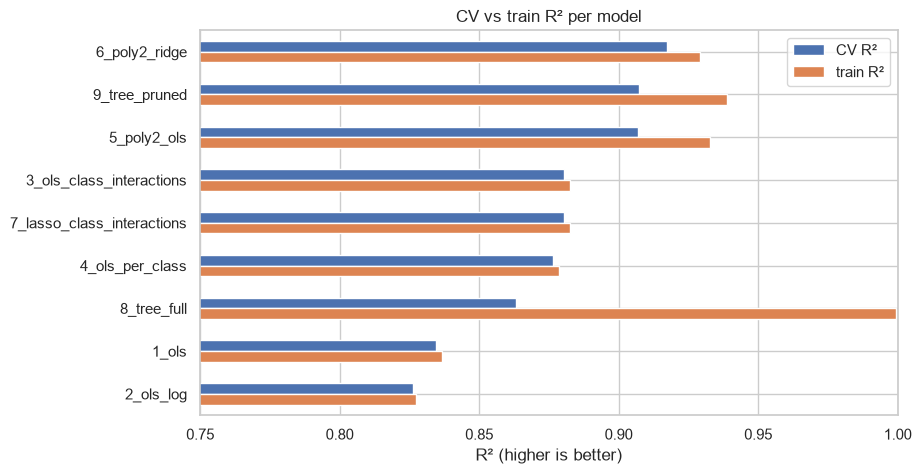

In [17]:
log = pd.read_csv(config.results_dir(TASK) / "experiments.csv")
table = (log[["model", "params", "r2_mean", "r2_std", "train_r2_mean", "rmse_mean", "public_lb"]]
         .sort_values("r2_mean", ascending=False).reset_index(drop=True))
display(table.round(4))

plot = table.dropna(subset=["train_r2_mean"]).set_index("model")[["r2_mean", "train_r2_mean"]]
ax = plot.rename(columns={"r2_mean": "CV R²", "train_r2_mean": "train R²"}).plot.barh(figsize=(9, 5))
ax.set(xlim=(0.75, 1.0), xlabel="R² (higher is better)", ylabel="", title="CV vs train R² per model")
ax.invert_yaxis()
plt.savefig(FIG_DIR / "models_r2.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations (Comparison)**

- **Ranking by CV R²:**
  1. Ridge on polynomial features (**0.9174**)
  2. pruned tree (0.9073)
  3. polynomial OLS (0.9070)
  4. class interactions, OLS or Lasso (0.880)
  5. separate per-class OLS (0.876)
  6. unpruned tree (0.863)
  7. OLS (0.835)
  8. log-target OLS (0.826)
  9. class-median baseline (0.289)
- **The ladder tells a consistent story:** every gain came from letting features **interact** (class × feature, then all pairs), which is exactly what EDA predicted. Every time the model became flexible enough to overfit, **controlling complexity** (Ridge's α, pruning the tree) bought the next gain.
- The chart shows the two failure modes side by side: OLS-type models have tiny train/CV gaps (high bias); the unpruned tree has a huge one (high variance).
- **Gap to the leaderboard top (≈ 0.96) is still ~0.04.** Phase 4 is about closing it.

## Submission of the best model so far

**What this cell does:** Fits the best model (by CV R²) on all training rows, predicts the test set, and writes a submission file.

**Why:** With 100 submissions a day this costs nothing, and it checks that CV and the public leaderboard agree on a real model, not just the baseline.

In [18]:
best_name = table.model.iloc[0]
best_model = {"6_poly2_ridge": lambda: ridge_poly(**ridge_best),
              "9_tree_pruned": lambda: tree(**tree_best)}[best_name]()
path, sub = evaluate.make_submission(best_model, X, y, X_test, test_ids, sample_sub, TASK, best_name)
print("best model:", best_name, "| saved:", path.name)
print(sub["price"].describe().round(0).to_string())

best model: 6_poly2_ridge | saved: 2026-10-11_6_poly2_ridge.csv
count      3898.0
mean      29641.0
std       38100.0
min       -7591.0
25%        7635.0
50%       11332.0
75%       37127.0
max      259660.0


**Observations (Submission)**

- Submitted model: **6_poly2_ridge** (α = 10), CV R² 0.9174, file `submissions/regression/2026-10-11_6_poly2_ridge.csv`.
- ⚠ **178 test predictions are below the cheapest training price (₹3,801), with a minimum of −₹7,591.** A linear model can extrapolate below zero for cheap Economy flights. In CV, flooring predictions at the lowest training price raises R² only slightly (0.9175 → 0.9183), because cheap tickets carry little weight in R². It's still clearly correct, so it's first on the Phase 4 list.
- **Kaggle public score: 0.94450** (CV 0.9174), up from 0.315 for the baseline, roughly 8th on the leaderboard at the time.
- Public is **0.027 above CV**, and the baseline showed almost the same offset (0.315 public vs 0.289 CV, +0.026). A similar offset for two very different models suggests it comes from the **public rows themselves** (R² depends on how spread out the prices are in the rows being scored) rather than luck. So it doesn't make CV less useful for *comparing* models; it just means public scores read ~0.03 higher than our CV.
- Recorded in `experiments.csv` → `public_lb`.

## Summary

| | CV R² |
|---|---|
| Baseline (class median) | 0.289 |
| Best linear: **Ridge on degree-2 polynomial features, α = 10** | **0.917** |
| Best tree: pruned (depth 12, leaf ≥ 5) | 0.907 |
| Kaggle top | ≈ 0.96 (public) |

**What Phase 3 established**
1. **Train on raw price, not log(price):** the log model under-predicts expensive tickets, which R² on raw price punishes.
2. **Interactions are where the signal is:** class × feature (+0.046), then all pairs (+0.027).
3. **Complexity control is necessary once the model is flexible:** Ridge (+0.010 over plain polynomial OLS) and pruning (+0.044 over the full tree).
4. **Weak features confirmed independently:** Lasso drops time slots, `days_left` and `stops`, as EDA predicted.

**Phase 4 ideas (tuning + features), in rough order of expected value**
1. Floor predictions at the minimum training price (small, certain gain).
2. Use the **flight code** itself. The pruned tree's reliance on `duration` and the EDA duplicates suggest that *which flight* it is carries a lot of price information. A regularised (Ridge) model can afford a one-hot of ~1,000 flight codes.
3. Add a **"last few days before departure" indicator** (EDA 2.5), since Lasso showed a linear `days_left` term is useless.
4. Finer α / degree tuning with validation curves for the report (bias–variance plots).